# Homework 4 — Evaluation (Machine Learning Zoomcamp 2026)

This notebook follows the [official 2026 assignment](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/04-evaluation/homework.md) and uses the [official 2026 lead-scoring CSV](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv). The target is `converted`.

Run from the repository root with **Restart Kernel and Run All**. Install dependencies with `python -m pip install -r 04_evaluation_requirements.txt`. The local CSV is an unchanged snapshot of the official release; if absent, it is downloaded from the official URL. Its SHA-256 is checked before use. Outputs include all answers, fold scores, and plots. The test set stays unused during evaluation and tuning.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import hashlib
import platform
import importlib.metadata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split, KFold

%matplotlib inline
np.random.seed(1)
warnings.filterwarnings('error', category=ConvergenceWarning)
pd.set_option('display.precision', 9)
print('Python:', platform.python_version())
for package in ['numpy', 'pandas', 'scikit-learn', 'scipy', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']:
    print(f'{package}: {importlib.metadata.version(package)}')

Python: 3.12.14
numpy: 2.5.3
pandas: 3.0.6
scikit-learn: 1.9.1
scipy: 1.18.1
matplotlib: 3.11.2
nbformat: 5.11.1
nbclient: 0.11.0
ipykernel: 7.3.0


## Data preparation

Inspect missing values before filling categorical features with `"NA"` and numerical features with `0.0`. These are fixed constants, so imputation learns no information from validation or test rows. No scaling, feature selection, stratification, or extra transformations are applied.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
DATA_PATH = Path('course_lead_scoring_2026.csv')
EXPECTED_SHA256 = '2d9da196bdefd2a45aa0a17ca21c19f06a5d9d56af628be1f04bbb3531cc12e9'
if not DATA_PATH.exists():
    urlretrieve(DATA_URL, DATA_PATH)
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_sha256 == EXPECTED_SHA256, 'Dataset changed; check the official release before proceeding.'
df = pd.read_csv(DATA_PATH)
assert df['converted'].notna().all()
assert set(df['converted'].unique()) == {0, 1}
print('Dataset SHA-256:', actual_sha256)
print('Dataset shape:', df.shape)
display(df.head())

features = df.columns.drop('converted').tolist()
numerical = df[features].select_dtypes(include='number').columns.tolist()
categorical = [c for c in features if c not in numerical]
missing_before = df.isna().sum()
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing_before': missing_before, 'missing_after': df.isna().sum()}))
assert not df.isna().any().any()
print('Categorical features:', categorical)
print('Numerical features:', numerical)

Dataset SHA-256: 2d9da196bdefd2a45aa0a17ca21c19f06a5d9d56af628be1f04bbb3531cc12e9
Dataset shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


,dtype,missing_before,missing_after
lead_source,str,148,0
industry,str,240,0
employment_status,str,194,0
location,str,208,0
annual_income,float64,369,0
number_of_courses_viewed,int64,0,0
interaction_count,int64,0,0
lead_score,float64,35,0
converted,int64,0,0


Categorical features: ['lead_source', 'industry', 'employment_status', 'location']
Numerical features: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [3]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Preserve the exact split order; .iloc is used for CV positions later.
y_train = df_train['converted'].to_numpy()
y_val = df_val['converted'].to_numpy()
assert set(df_train.index).isdisjoint(df_val.index)
assert set(df_full_train.index).isdisjoint(df_test.index)
display(pd.DataFrame({'split': ['train', 'validation', 'test', 'full_train'],
                      'rows': [len(df_train), len(df_val), len(df_test), len(df_full_train)]}))

,split,rows
0,train,3000
1,validation,1000
2,test,1000
3,full_train,4000


## Q1 — ROC AUC feature importance

Use each numerical feature as a score on the training split. When raw AUC is below 0.5, recompute it using the negative feature. Compare all numerical features and select the highest AUC among the four official choices.

In [4]:
feature_rows = []
for feature in numerical:
    raw_auc = roc_auc_score(y_train, df_train[feature])
    reverse = raw_auc < 0.5
    score = -df_train[feature] if reverse else df_train[feature]
    feature_rows.append({'feature': feature, 'raw_auc': raw_auc, 'reversed': reverse,
                         'auc': roc_auc_score(y_train, score)})
feature_auc = pd.DataFrame(feature_rows).sort_values('auc', ascending=False)
display(feature_auc.reset_index(drop=True))
q1_options = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
q1 = feature_auc[feature_auc.feature.isin(q1_options)].iloc[0]
print(f"Q1: {q1['feature']} (AUC = {q1['auc']:.9f})")

,feature,raw_auc,reversed,auc
0,lead_score,0.788225481,False,0.788225481
1,interaction_count,0.764920305,False,0.764920305
2,number_of_courses_viewed,0.722989462,False,0.722989462
3,annual_income,0.608197778,False,0.608197778


Q1: lead_score (AUC = 0.788225481)


## Q2 — Logistic regression validation AUC

Fit `DictVectorizer` on training rows only, then transform validation rows with the same vocabulary. All eight predictor columns are used; `converted` is excluded. Use the exact requested model parameters and round the validation AUC to three decimals.

In [5]:
def train(frame, C=1.0):
    vectorizer = DictVectorizer(sparse=False)
    X = vectorizer.fit_transform(frame[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, frame['converted'].to_numpy())
    return vectorizer, model

def predict(frame, vectorizer, model):
    X = vectorizer.transform(frame[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train)
y_pred = predict(df_val, dv, model)
val_auc = roc_auc_score(y_val, y_pred)
q2 = round(float(val_auc), 3)
print(f'Validation AUC: {val_auc:.9f}')
print(f'Q2 (3 decimals): {q2:.3f}')

Validation AUC: 0.731822229
Q2 (3 decimals): 0.732


## Q3 — Precision and recall across thresholds

A prediction is positive when its probability is **greater than or equal to** the threshold. Evaluate every threshold from 0.00 through 1.00 in steps of 0.01. Undefined precision/recall is set to zero. Follow the official intersection rule: exclude rows where both metrics are zero, then minimize their absolute difference over the entire grid.

,intersection
threshold,0.630000000
precision,0.732758621
recall,0.725255973
absolute_difference,0.007502648


Q3: threshold = 0.63


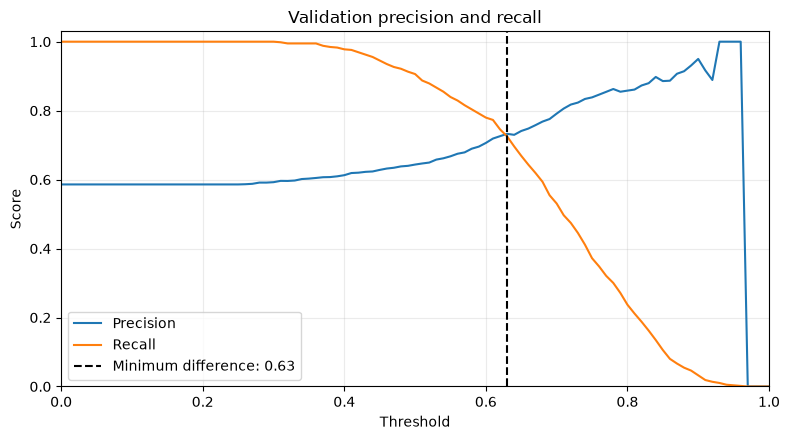

In [6]:
thresholds = np.round(np.arange(101) / 100, 2)
metric_rows = []
for threshold in thresholds:
    positive = y_pred >= threshold
    metric_rows.append({'threshold': threshold,
                        'precision': precision_score(y_val, positive, zero_division=0),
                        'recall': recall_score(y_val, positive, zero_division=0)})
metrics = pd.DataFrame(metric_rows)
metrics['absolute_difference'] = (metrics.precision - metrics.recall).abs()
eligible = metrics[(metrics.precision != 0) | (metrics.recall != 0)]
intersection = eligible.loc[eligible.absolute_difference.idxmin()]
q3 = float(intersection.threshold)
display(intersection.to_frame('intersection'))
print(f'Q3: threshold = {q3:.2f}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(metrics.threshold, metrics.precision, label='Precision')
ax.plot(metrics.threshold, metrics.recall, label='Recall')
ax.axvline(q3, color='black', linestyle='--', label=f'Minimum difference: {q3:.2f}')
ax.set(xlabel='Threshold', ylabel='Score', title='Validation precision and recall', xlim=(0, 1), ylim=(0, 1.03))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Q4 — Maximum F1

Compute the harmonic mean $F_1 = 2PR/(P+R)$ at every threshold in the same grid, using zero when the denominator is zero. Select the maximum across all 101 thresholds, then match its threshold to an official option.

,maximum_f1
threshold,0.410000000
precision,0.619047619
recall,0.976109215
absolute_difference,0.357061596
f1,0.757615894


Q4: threshold = 0.41; maximum F1 = 0.757615894
All thresholds attaining the maximum: [0.41]


,threshold,precision,recall,absolute_difference,f1
0,0.00,0.586000000,1.000000000,0.414000000,0.738965952
1,0.01,0.586000000,1.000000000,0.414000000,0.738965952
2,0.02,0.586000000,1.000000000,0.414000000,0.738965952
3,0.03,0.586000000,1.000000000,0.414000000,0.738965952
4,0.04,0.586000000,1.000000000,0.414000000,0.738965952
5,0.05,0.586000000,1.000000000,0.414000000,0.738965952
6,0.06,0.586000000,1.000000000,0.414000000,0.738965952
7,0.07,0.586000000,1.000000000,0.414000000,0.738965952
8,0.08,0.586000000,1.000000000,0.414000000,0.738965952
9,0.09,0.586000000,1.000000000,0.414000000,0.738965952


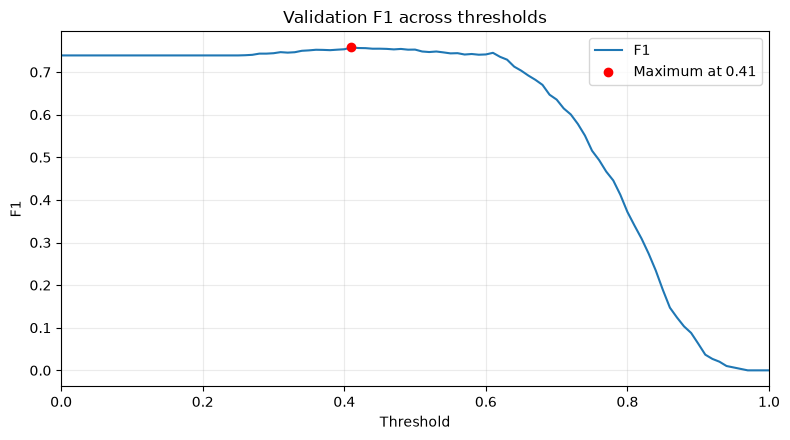

In [7]:
denominator = metrics.precision + metrics.recall
metrics['f1'] = np.divide(2 * metrics.precision * metrics.recall, denominator,
                          out=np.zeros(len(metrics)), where=denominator.to_numpy() != 0)
best_f1 = metrics.loc[metrics.f1.idxmax()]
q4 = float(best_f1.threshold)
assert np.isclose(best_f1.f1, f1_score(y_val, y_pred >= q4, zero_division=0))
display(best_f1.to_frame('maximum_f1'))
print(f'Q4: threshold = {q4:.2f}; maximum F1 = {best_f1.f1:.9f}')
print('All thresholds attaining the maximum:', metrics.loc[metrics.f1 == best_f1.f1, 'threshold'].tolist())
with pd.option_context('display.max_rows', 101):
    display(metrics)  # Saved values for all 101 thresholds.

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(metrics.threshold, metrics.f1, label='F1')
ax.scatter([q4], [best_f1.f1], color='red', zorder=3, label=f'Maximum at {q4:.2f}')
ax.set(xlabel='Threshold', ylabel='F1', title='Validation F1 across thresholds', xlim=(0, 1))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Q5 — Five-fold cross-validation

Use `df_full_train`, preserving its row order. Each fold trains a fresh vectorizer and model, so the vocabulary never sees its validation rows during fitting. Report all five AUCs, their mean, and their population standard deviation (`np.std`, `ddof=0`). The test set is not used.

In [8]:
def cross_validate(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for fold_train_idx, fold_val_idx in kfold.split(df_full_train):
        fold_train = df_full_train.iloc[fold_train_idx]
        fold_val = df_full_train.iloc[fold_val_idx]
        fold_dv, fold_model = train(fold_train, C=C)
        fold_pred = predict(fold_val, fold_dv, fold_model)
        scores.append(roc_auc_score(fold_val['converted'], fold_pred))
    return np.array(scores)

scores_c1 = cross_validate(1.0)
display(pd.DataFrame({'fold': np.arange(1, 6), 'auc': scores_c1}))
cv_mean = float(np.mean(scores_c1))
cv_std = float(np.std(scores_c1, ddof=0))
q5 = round(cv_std, 3)
print(f'Mean AUC: {cv_mean:.9f}')
print(f'Standard deviation (ddof=0): {cv_std:.9f}')
print(f'Q5 (3 decimals): {q5:.3f}')

,fold,auc
0,1,0.730560103
1,2,0.729572615
2,3,0.736342807
3,4,0.741245472
4,5,0.720913859


Mean AUC: 0.731726971
Standard deviation (ddof=0): 0.006853233
Q5 (3 decimals): 0.007


## Q6 — Tune C with the same five folds

Evaluate `C` in `[0.000001, 0.001, 1]`. Round both the mean and standard deviation to three decimal places **before comparing**: choose the highest rounded mean, then the lowest rounded standard deviation, then the smallest C. Keep unrounded values and individual fold scores visible for auditability. `C=1` reuses the identical Q5 calculation.

In [9]:
cv_rows = []
for C in [0.000001, 0.001, 1]:
    scores = scores_c1 if C == 1 else cross_validate(C)
    mean, std = float(np.mean(scores)), float(np.std(scores, ddof=0))
    row = {'C': C, 'mean_auc': mean, 'std_auc': std,
           'mean_rounded': round(mean, 3), 'std_rounded': round(std, 3)}
    row.update({f'fold_{i}': score for i, score in enumerate(scores, start=1)})
    cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows)
display(cv_results)
print(cv_results[['C', 'mean_rounded', 'std_rounded']].to_string(index=False, formatters=
    {'C': '{:g}'.format, 'mean_rounded': '{:.3f}'.format, 'std_rounded': '{:.3f}'.format}))
ranked = cv_results.sort_values(['mean_rounded', 'std_rounded', 'C'], ascending=[False, True, True])
q6 = float(ranked.iloc[0]['C'])
print(f'Q6: C = {q6:g}')

,C,mean_auc,std_auc,mean_rounded,std_rounded,fold_1,fold_2,fold_3,fold_4,fold_5
0,0.000001,0.616734225,0.018669799,0.617,0.019,0.594100465,0.640213724,0.600157038,0.636446693,0.612753204
1,0.001000,0.749172178,0.009996375,0.749,0.010,0.750434922,0.747533339,0.758353929,0.758412717,0.731125982
2,1.000000,0.731726971,0.006853233,0.732,0.007,0.730560103,0.729572615,0.736342807,0.741245472,0.720913859


    C mean_rounded std_rounded
1e-06        0.617       0.019
0.001        0.749       0.010
    1        0.732       0.007
Q6: C = 0.001


## Calculated answers and official choices

The checks below require exact matching after the specified rounding. They do not pick the nearest available option.

In [10]:
assert q1['feature'] in q1_options
assert q2 in [0.532, 0.632, 0.732, 0.832]
assert q3 in [0.43, 0.63, 0.73, 0.83]
assert q4 in [0.21, 0.41, 0.61, 0.81]
assert q5 in [0.001, 0.007, 0.013, 0.060]
assert q6 in [0.000001, 0.001, 1]
answers = pd.DataFrame([
    ['Q1', f"{q1['feature']}: AUC {q1['auc']:.9f}", q1['feature']],
    ['Q2', f'{val_auc:.9f}', f'{q2:.3f}'],
    ['Q3', f'threshold {q3:.2f}; P={intersection.precision:.9f}, R={intersection.recall:.9f}', f'{q3:.2f}'],
    ['Q4', f'threshold {q4:.2f}; F1={best_f1.f1:.9f}', f'{q4:.2f}'],
    ['Q5', f'mean={cv_mean:.9f}; std={cv_std:.9f}', f'{q5:.3f}'],
    ['Q6', f'C={q6:g}', f'{q6:g}'],
], columns=['question', 'calculated_result', 'official_choice'])
display(answers)
print('All six results exactly match official choices after required rounding.')

,question,calculated_result,official_choice
0,Q1,lead_score: AUC 0.788225481,lead_score
1,Q2,0.731822229,0.732
2,Q3,"threshold 0.63; P=0.732758621, R=0.725255973",0.63
3,Q4,threshold 0.41; F1=0.757615894,0.41
4,Q5,mean=0.731726971; std=0.006853233,0.007
5,Q6,C=0.001,0.001


All six results exactly match official choices after required rounding.


## Study notes

- **ROC AUC** measures ranking quality across classification thresholds: the probability that a randomly selected positive receives a higher score than a randomly selected negative (ties count half). AUC 0.5 is random ranking; 1.0 is perfect ranking. It does not measure probability calibration.
- **Precision** is `TP / (TP + FP)`: among predicted conversions, how many really converted?
- **Recall** is `TP / (TP + FN)`: among actual conversions, how many did the model identify?
- **F1** is the harmonic mean of precision and recall. It rewards a balance between them, ignores true negatives, and depends on the decision threshold.
- **Cross-validation** repeatedly holds out a different fold while training on the others. Mean AUC summarizes performance across held-out folds; standard deviation describes variation between those folds, not a confidence interval. Preprocessing must be fitted inside each training fold to avoid leakage.

Increasing the threshold usually reduces the number of positive predictions, trading recall for precision (precision need not increase monotonically). Smaller `C` means stronger logistic regression regularization. Threshold selection and C tuning use training/validation data only; a final test score would be a separate later step.

No submission, public post, commit, or push is performed by this notebook.